# Lab05 - Metoda składowych głównych

### 1) wczytanie emoji

In [1]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pywt
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

In [2]:
def load_emojis(folder_name="emojis"):
    script_dir = globals()['_dh'][0]
    script_dir = os.path.join(script_dir, "..")
    folder_path = os.path.join(script_dir, folder_name)
    if not os.path.isdir(folder_path):
        raise FileNotFoundError(f"Nie znaleziono folderu z emoji: {folder_path}")

    emojis = {}
    for filename in sorted(os.listdir(folder_path)):
        if filename.lower().endswith(".png"):
            emoji_name = os.path.splitext(filename)[0]
            emoji_path = os.path.join(folder_path, filename)
            emoji_image = cv2.imread(emoji_path, cv2.IMREAD_UNCHANGED)
            if emoji_image is None:
                raise OSError(f"Nie można wczytać obrazu emoji: {emoji_path}")

            emoji_gray = cv2.cvtColor(emoji_image[:, :, :3], cv2.COLOR_BGR2GRAY)

            alpha = emoji_image[:, :, 3].astype(np.float32) / 255.0
            emoji_gray = emoji_gray.astype(np.float32) / 255.0
            emojis[emoji_name] = (emoji_gray * alpha + (1.0 - alpha))

    if not emojis:
        raise ValueError(f"Folder nie zawiera plików PNG z emoji: {folder_path}")

    return emojis

In [3]:
emojis = load_emojis()
if not emojis:
    raise ValueError("Brak poprawnie załadowanych emojis.")

### 2) wydobycie cech FFT / wavelet

In [4]:
def extract_fft_features(img):
    f = np.fft.fft2(img)
    fshift = np.fft.fftshift(f)
    magnitude_spectrum = np.abs(fshift)
    return magnitude_spectrum.flatten()

In [5]:
def extract_haar_features(img, level=2):
    coeffs = pywt.wavedec2(img, wavelet='haar', level=level)
    cA2, (cH2, cV2, cD2), (cH1, cV1, cD1) = coeffs
    
    features = np.concatenate([
        cA2.flatten(), 
        cH2.flatten(), cV2.flatten(), cD2.flatten(),
        cH1.flatten(), cV1.flatten(), cD1.flatten()
    ])
    return features

### 3) przygotowanie cech do PCA

In [6]:
# Do metody Early Fusion potrzebna jest normalizacja

def normalize_vector(v):
    norm = np.linalg.norm(v)
    return v / norm if norm > 0 else v

In [7]:
def prepare_all_features(emojis_dict):
    names = list(emojis_dict.keys())
    X_fft, X_haar, X_early = [], [], []
    
    for name in names:
        img = emojis_dict[name]
        
        fft_feat = extract_fft_features(img)
        haar_feat = extract_haar_features(img)
        early_feat = np.concatenate([normalize_vector(fft_feat), normalize_vector(haar_feat)])
        
        X_fft.append(fft_feat)
        X_haar.append(haar_feat)
        X_early.append(early_feat)
        
    return names, np.array(X_fft), np.array(X_haar), np.array(X_early)

### 4) PCA

In [8]:
def retrieve_best_match_pca(query_name, emojis_dict, n_components):
    names, X_fft, X_haar, X_early = prepare_all_features(emojis_dict)
    query_idx = names.index(query_name)
    
    # Baza danych to wszystko oprócz query
    db_names = [n for i, n in enumerate(names) if i != query_idx]
    
    results = {}
    feature_sets = {
        "FFT + PCA": X_fft,
        "Haar + PCA": X_haar,
        "Early Fusion + PCA": X_early
    }
    
    for method_name, X_data in feature_sets.items():
        X_db = np.delete(X_data, query_idx, axis=0)
        X_query = X_data[query_idx].reshape(1, -1)
        actual_components = min(n_components, len(db_names))
        
        # PCA redukuje wymiarowość danych do n_components
        pca = PCA(n_components=actual_components)
        X_db_pca = pca.fit_transform(X_db)
        X_query_pca = pca.transform(X_query)
        
        # Znajdujemy najbliższego sąsiada w bazie danych
        knn = NearestNeighbors(n_neighbors=1, metric='euclidean')
        knn.fit(X_db_pca)
        distances, indices = knn.kneighbors(X_query_pca)
        
        best_match = db_names[indices[0][0]]
        best_dist = distances[0][0]
        results[method_name] = (best_match, best_dist)
        
    return results

### 5) Przedstawienie wyników

In [9]:
def show_results(query_name, emojis, n_comp=8, no_print=False):
    if not no_print:
        print(f"Szukany wzorzec: {query_name}")
        print("-" * 50)

    results_pca = retrieve_best_match_pca(query_name, emojis, n_comp)

    for method, (best_name, best_dist) in results_pca.items():
        if not no_print:
            print(f"Metoda: {method:20} | Najlepsze dopasowanie: {best_name} (Dystans: {best_dist:.4f})")

        methods = list(results_pca.keys())

    plt.figure(figsize=(12, 4))
    plt.subplot(1, len(methods) + 1, 1)
    plt.imshow(emojis[query_name], cmap="gray", vmin=0, vmax=1)
    plt.title("Query\n(Wzorzec)")
    plt.axis("off")

    for idx, method in enumerate(methods):
        best_name, best_dist = results_pca[method]
        best_img = emojis[best_name]
        
        plt.subplot(1, len(methods) + 1, idx + 2)
        plt.imshow(best_img, cmap="gray", vmin=0, vmax=1)
        plt.title(f"{method}\n{best_name}\nDist: {best_dist:.2f}")
        plt.axis("off")

    plt.tight_layout()
    plt.suptitle(f"Wyszukiwanie z PCA (n_components={n_comp})", fontsize=16, y=1.1)
    plt.show()

### 6) Przykładowe wyniki + wnioski

Szukany wzorzec: 1F602
--------------------------------------------------
Metoda: FFT + PCA            | Najlepsze dopasowanie: 1F60D (Dystans: 325.9362)
Metoda: Haar + PCA           | Najlepsze dopasowanie: 1F928 (Dystans: 6.3127)
Metoda: Early Fusion + PCA   | Najlepsze dopasowanie: 1F62D (Dystans: 0.1267)


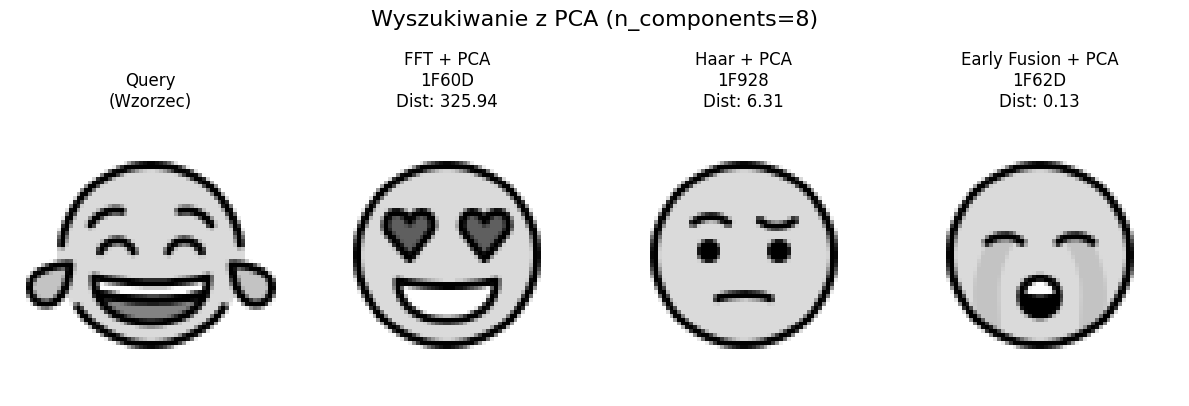

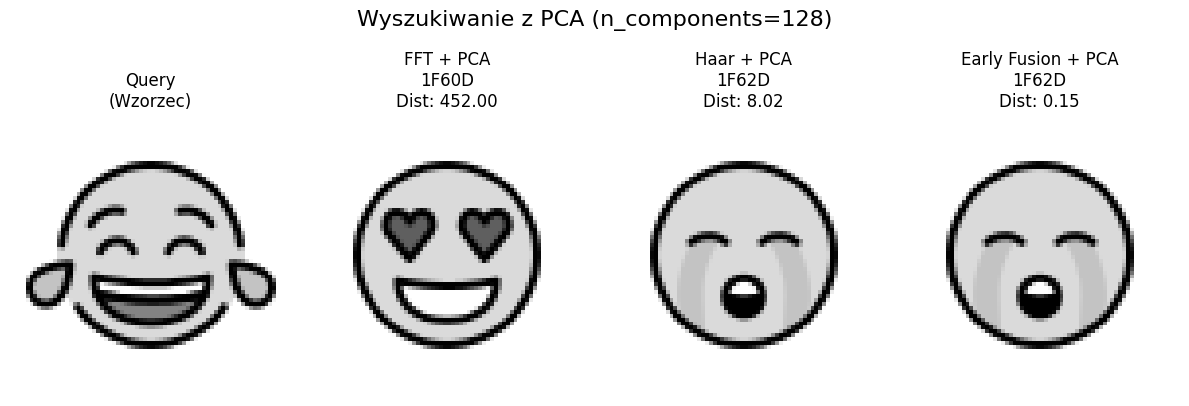

Szukany wzorzec: 1F60D
--------------------------------------------------
Metoda: FFT + PCA            | Najlepsze dopasowanie: 1F62B (Dystans: 317.9226)
Metoda: Haar + PCA           | Najlepsze dopasowanie: 1F928 (Dystans: 5.1273)
Metoda: Early Fusion + PCA   | Najlepsze dopasowanie: 1F928 (Dystans: 0.1019)


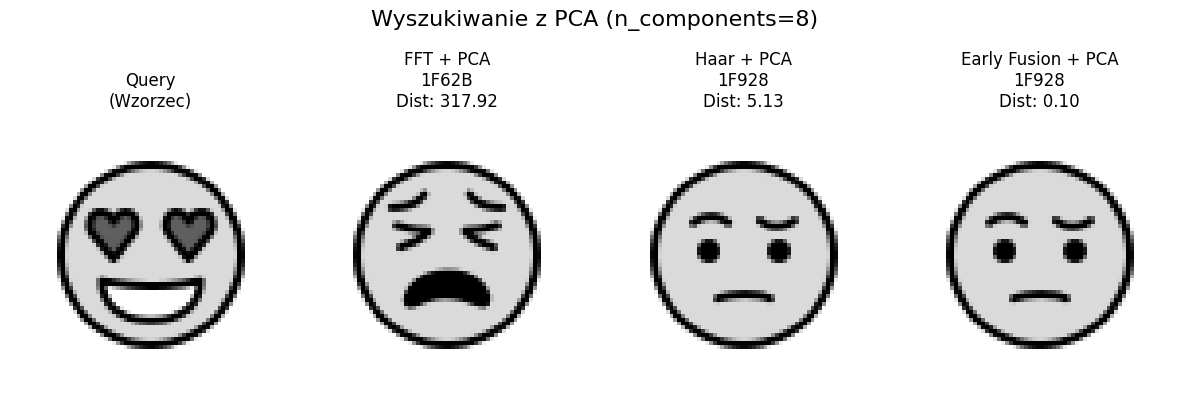

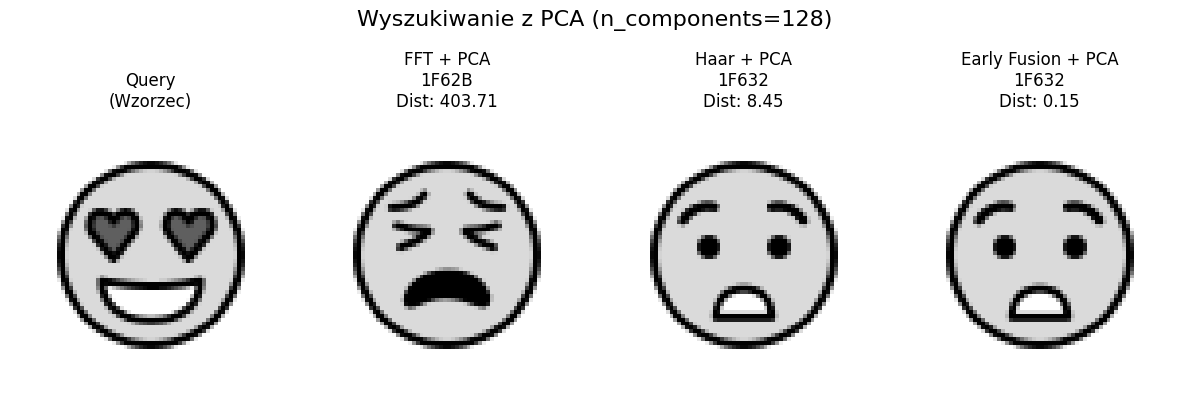

Szukany wzorzec: 1F630
--------------------------------------------------
Metoda: FFT + PCA            | Najlepsze dopasowanie: 1F62D (Dystans: 220.3748)
Metoda: Haar + PCA           | Najlepsze dopasowanie: 1F642 (Dystans: 3.7759)
Metoda: Early Fusion + PCA   | Najlepsze dopasowanie: 1F642 (Dystans: 0.0719)


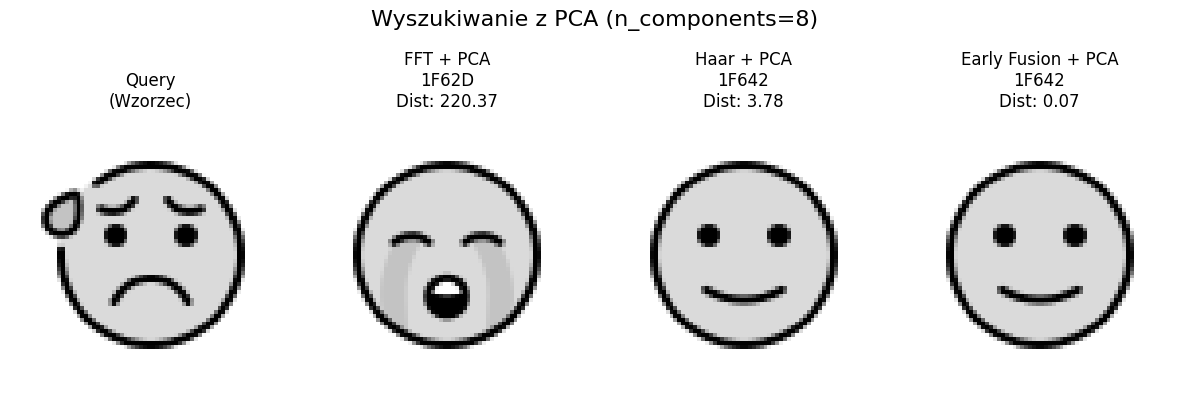

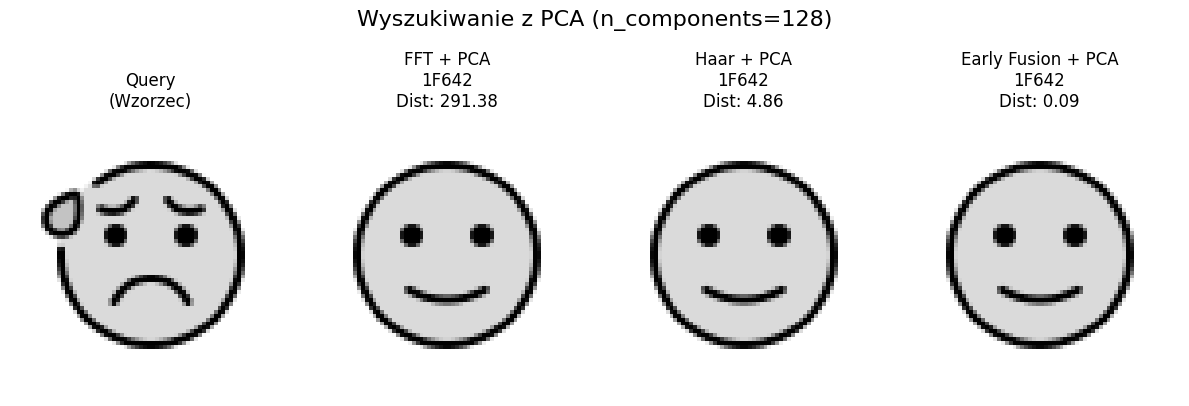

In [10]:
show_results("1F602", emojis, n_comp=8)
show_results("1F602", emojis, n_comp=128, no_print=True)
show_results("1F60D", emojis, n_comp=8)
show_results("1F60D", emojis, n_comp=128, no_print=True)
show_results("1F630", emojis, n_comp=8)
show_results("1F630", emojis, n_comp=128, no_print=True)

**Wnioski**:
 - Nawet dla małych `n_comp` fuzja FFT i Falki Haara radzi sobie dobrze (porównywalnie z poprzednim labem). Jest to spowodowane tym że fuzja dobrze kompensuje wady obu reprezentacji. (Utrata informacji przestrzennej w FFT i brak ogólnego spojrzenia w falce)
 - Dystans na poziomie paru setnych w fuzji jest spowodowany normalizacją danych przed ich połączeniem. Dzięki normalizacji wyższe dystanse w FFT nie dominują nad niższymi w falce Haara.
 - FFT nie zwraca uwagi na umiejscowienie, a zwiększenie `n_comp` rzadko kiedy zmienia wynik.
 - Dla wyższych `n_comp` falka Haara radzi sobie porównywalnie z fuzją (i poprzednim labem).